# P2.03 — Do pressures spill over between neighbouring municipalities?

**Question:** RQ4.4. P2.01 found that neighbours resemble each other, and that most of the resemblance is
regional. This notebook asks the harder question with the fixed-effects model of P2.02: once a municipality's
own drivers and its region's yearly shocks are accounted for, do its *neighbours* still matter?

Three tests, each with queen-contiguity weights (a neighbour's value is averaged, `spatial_lag`):
1. **Leftover clustering:** is the residual of the regression still spatially correlated (Moran's I)?
2. **Neighbours' drivers (SLX):** do the drivers of the neighbours (foreign residents, other population, completions)
   help explain a municipality's own price-to-income?
3. **Diffusion with a placebo:** does the neighbours' price-to-income *last year* predict a municipality's own this
   year? If prices spread from place to place, last year's neighbours should matter and *next year's* neighbours
   (which cannot cause anything today) should not. If both matter equally, the link is shared local shocks.

All models use municipality effects, with year effects or the harder NUTS 3 × year effects, and the standard
errors are clustered by municipality. Results are adjusted associations.

In [1]:
import pandas as pd

from pthousing.analysis import panel as pn
from pthousing.analysis import spatial
from pthousing.data import build_panel, interim
from pthousing.viz import charts, style

style.apply_style()
geo = interim.read("caop_municipalities")
w = spatial.build_weights(geo)
frame = pn.build_frame(build_panel.read("panel_municipality_year"))
X = [
    "pop_change_ex_foreign_pct",
    "foreign_change_pct",
    "completions_per_1000",
    "pop_65plus_pct",
]
WX = [f"w_{c}" for c in X[:3]]  # neighbours' drivers (ageing is slow-moving and not significant)
frame = pn.add_spatial_lags(frame, w, [*X[:3], "log_pti"])
frame = pn.add_spatial_lags(frame, w, ["log_pti"], shift=1)  # neighbours last year
frame = pn.add_spatial_lags(frame, w, ["log_pti"], shift=-1)  # neighbours next year (placebo)
frame["log_pti_l1"] = frame.groupby(level="muni_code")["log_pti"].shift(1)
frame["log_pti_f1"] = frame.groupby(level="muni_code")["log_pti"].shift(-1)
WINDOW = (2017, 2022)  # years with both a last-year and a next-year value
MAIN, COMPARE = "Municipality + year", "Municipality + region-year"
EFFECTS = {MAIN: "year", COMPARE: "region_year"}

## Test 1 — Is the residual still spatially correlated?

In [2]:
rows = []
fits = {}
for name, effects in EFFECTS.items():
    res = pn.fit(frame, pn.Spec("log_pti", X, effects=effects), years=WINDOW)
    fits[name] = res
    resid = pn.residuals_by_year(res).rename(columns={"residual": "resid"})
    moran = spatial.moran_by_year(resid, "resid", w, list(range(WINDOW[0], WINDOW[1] + 1)))
    rows.append(moran.assign(effects=name))
resid_moran = pd.concat(rows, ignore_index=True)
style.save_table(
    resid_moran[["effects", "year", "I", "z_sim", "p_sim", "n"]], "p2", "spillover_residual_moran"
)
print(resid_moran.pivot(index="year", columns="effects", values="I").round(3).to_string())
print(resid_moran.pivot(index="year", columns="effects", values="p_sim").round(3).to_string())

effects  Municipality + region-year  Municipality + year
year                                                    
2017                          0.021                0.178
2018                          0.016                0.146
2019                         -0.110               -0.010
2020                          0.005                0.045
2021                         -0.048                0.021
2022                         -0.024                0.281
effects  Municipality + region-year  Municipality + year
year                                                    
2017                          0.254                0.001
2018                          0.271                0.002
2019                          0.005                0.432
2020                          0.412                0.114
2021                          0.133                0.265
2022                          0.292                0.001


## Test 2 — Do the neighbours' drivers matter? (SLX)

In [3]:
slx = pd.concat(
    [
        pn.coef_table(pn.fit(frame, pn.Spec("log_pti", [*X, *WX], effects=eff)), f"SLX, {name}")
        for name, eff in EFFECTS.items()
    ],
    ignore_index=True,
)
style.save_table(slx, "p2", "spillover_slx")
shown = slx.assign(term=slx["term"].map(lambda t: pn.LABELS.get(t, t)))
print(
    shown[["spec", "term", "coef", "se", "p", "coef_per_sd", "r2"]].round(4).to_string(index=False)
)

                           spec                                       term    coef     se      p  coef_per_sd     r2
       SLX, Municipality + year       Other population change (pp of pop.)  0.0045 0.0027 0.0947       0.0064 0.1134
       SLX, Municipality + year       Foreign resident change (pp of pop.)  0.0260 0.0091 0.0043       0.0123 0.1134
       SLX, Municipality + year Completions, 3 years (per 1,000 dwellings)  0.0073 0.0022 0.0008       0.0145 0.1134
       SLX, Municipality + year                   Population aged 65+ (pp) -0.0070 0.0065 0.2827      -0.0057 0.1134
       SLX, Municipality + year                w_pop_change_ex_foreign_pct  0.0130 0.0041 0.0015       0.0131 0.1134
       SLX, Municipality + year                       w_foreign_change_pct  0.0307 0.0130 0.0183       0.0102 0.1134
       SLX, Municipality + year                     w_completions_per_1000  0.0215 0.0044 0.0000       0.0262 0.1134
SLX, Municipality + region-year       Other population change (p

## Test 3 — Diffusion against shared shocks (lag and lead placebo)

In [4]:
SPECS = {
    "lag": ["w_log_pti_l1"],
    "lead": ["w_log_pti_f1"],
    "own_lag": ["log_pti_l1", "w_log_pti_l1"],
    "own_lead": ["log_pti_f1", "w_log_pti_f1"],
}
tests = []
for name, effects in EFFECTS.items():
    for key, extra in SPECS.items():
        res = pn.fit(frame, pn.Spec("log_pti", [*X, *extra], effects=effects, years=WINDOW))
        tests.append(pn.coef_table(res, f"{name}|{key}"))
diffusion = pd.concat(tests, ignore_index=True)
style.save_table(diffusion, "p2", "spillover_diffusion")
keep = diffusion[diffusion["term"].str.contains("log_pti")]
print(keep[["spec", "term", "coef", "se", "p", "n_obs"]].round(3).to_string(index=False))

                               spec         term   coef    se     p  n_obs
            Municipality + year|lag w_log_pti_l1  0.353 0.069 0.000   1745
           Municipality + year|lead w_log_pti_f1  0.418 0.067 0.000   1744
        Municipality + year|own_lag   log_pti_l1  0.076 0.050 0.128   1720
        Municipality + year|own_lag w_log_pti_l1  0.330 0.067 0.000   1720
       Municipality + year|own_lead   log_pti_f1  0.052 0.051 0.311   1715
       Municipality + year|own_lead w_log_pti_f1  0.416 0.067 0.000   1715
     Municipality + region-year|lag w_log_pti_l1  0.183 0.086 0.034   1745
    Municipality + region-year|lead w_log_pti_f1  0.116 0.092 0.206   1744
 Municipality + region-year|own_lag   log_pti_l1  0.021 0.050 0.674   1720
 Municipality + region-year|own_lag w_log_pti_l1  0.190 0.083 0.023   1720
Municipality + region-year|own_lead   log_pti_f1 -0.011 0.054 0.843   1715
Municipality + region-year|own_lead w_log_pti_f1  0.159 0.099 0.109   1715


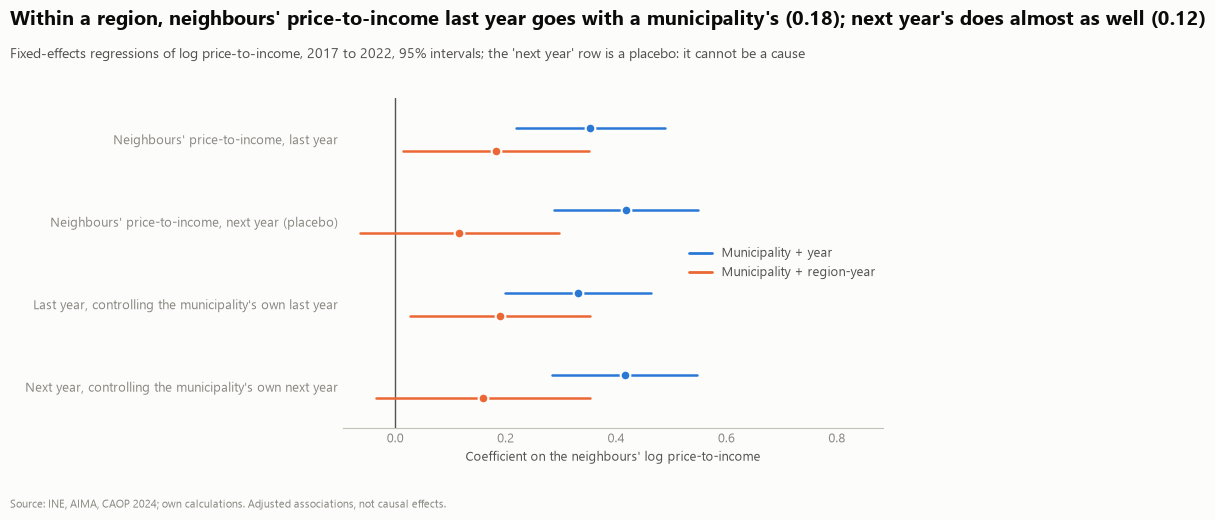

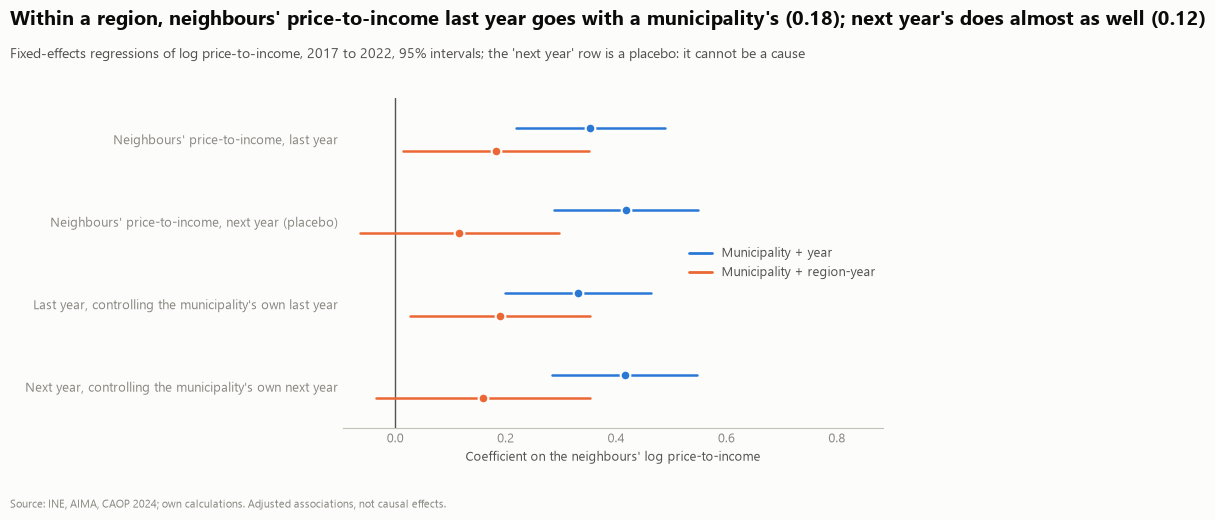

In [5]:
labels = {
    "lag": "Neighbours' price-to-income, last year",
    "lead": "Neighbours' price-to-income, next year (placebo)",
    "own_lag": "Last year, controlling the municipality's own last year",
    "own_lead": "Next year, controlling the municipality's own next year",
}
fig = charts.neighbour_placebo(diffusion, labels, MAIN, COMPARE)
style.save_fig(fig, "p2", "spillover_placebo")
fig

## Findings

1. **The leftover clustering was regional.** With municipality and year effects the residuals are still spatially
   correlated in several years (Moran's I 0.18 in 2017, 0.15 in 2018, 0.28 in 2022; p ≤ 0.002). With NUTS 3 × year
   effects none is positive and significant (I between −0.11 and 0.02), so there is no sign that neighbours' shocks distort the standard errors of the NUTS 3 × year
   models. The one significant value is negative (2019, −0.11) and is one of
   twelve tests.
2. **Neighbours' drivers matter only through the region.** With year effects, the neighbours' completions (+2.2% per
   dwelling per 1,000, larger than the municipality's own +0.7%), other population change (+1.3%) and foreign-resident
   change (+3.1%) are all associated with a municipality's price-to-income. With NUTS 3 × year effects none is
   (p = 0.11, 0.56, 0.30); the municipality's own foreign-resident change stays (+2.7%, p = 0.002).
3. **Diffusion cannot be separated from shared shocks.** With year effects, the neighbours' price-to-income last year
   goes with a municipality's (coefficient 0.35, p < 0.001) but so does next year's, which cannot be a cause (0.42):
   the link is a shared regional pattern. With NUTS 3 × year effects last year's coefficient is 0.18 (p = 0.034;
   0.19 when the municipality's own last year is controlled, p = 0.023) and the placebo next-year coefficient is
   smaller and not significant (0.12, p = 0.21; 0.16, p = 0.11). The sign and size are the same, and the two
   are not statistically separated: the evidence for diffusion between neighbours is weak at best.
4. **Answer to RQ4.4.** Municipalities cluster strongly, mostly because they share a region. Beyond that, little
   evidence of spillovers: no clustering is left in the residuals, neighbours' drivers do not help, and the one
   hint (neighbours' past price-to-income) is matched by a placebo.

**Limits.** NUTS 3 × year effects also absorb any spillover that spreads across a whole region (for example from
the Lisboa centre through its sub-region), so the test is conservative: it asks whether neighbours matter *beyond* the
regional pattern. Queen contiguity treats very unequal municipalities alike. Own-lag coefficients in a fixed-effects
model with eight years are biased (Nickell), and a municipality's own and its neighbours' lagged price-to-income are
highly correlated (0.83). Twelve residual tests and many coefficients: single p-values near 0.03 are not firm.
The sample is 2017 to 2022. These are not spatial-lag or spatial-error panel models (`spreg` is not installed); they
are the space-time and SLX forms that fixed-effects regression can estimate directly.